# 9. Linearization and stability

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/09_linearization_and_stability.ipynb)

Real systems are nonlinear, but almost all of control theory and vibration analysis is linear.
The bridge is linearization about a steady state, and the question it answers is
"if the system is disturbed slightly, does it return?"

The procedure never changes, and every step is one SymPy call:

1. find the steady states: `sp.solve`
2. differentiate the model there: `Matrix.jacobian`
3. inspect the eigenvalues: `Matrix.eigenvals`. All real parts negative means stable.

**Worked examples:** a draining tank, a damped pendulum, and washout in a continuous bioreactor.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 9.1 One state: a tank draining through a valve

**Problem.** Liquid enters a tank of cross-section $A$ at flow rate $q$ and leaves through a
valve at a rate $c\sqrt{h}$, where $h$ is the level:

$$A\frac{dh}{dt} = q - c\sqrt{h}.$$

Find a linear model for small changes around a steady state.

**By hand.** Expand the right-hand side in a Taylor series about $(h_s, q_s)$ and keep the
first-order terms.

In [2]:
h, q, A, c = sp.symbols("h q A c", positive=True)
h_s, q_s = sp.symbols("h_s q_s", positive=True)

dhdt = (q - c * sp.sqrt(h)) / A

steady_level = sp.solve(dhdt.subs(q, q_s), h)[0]
steady_level

  2
qₛ 
───
 2 
c  

In [3]:
# sensitivities at the steady state
a_coeff = sp.diff(dhdt, h).subs(h, h_s)      # effect of a level change
b_coeff = sp.diff(dhdt, q)                   # effect of an inflow change
a_coeff, b_coeff

⎛   -c       1⎞
⎜──────────, ─⎟
⎜      ____  A⎟
⎝2⋅A⋅╲╱ hₛ    ⎠

In deviation variables $h' = h - h_s$, $q' = q - q_s$ the linear model is
$\dot h' = a\,h' + b\,q'$, a first-order process $\tau\,\dot h' + h' = K q'$ with

In [4]:
tau = sp.simplify(-1 / a_coeff)
gain = sp.simplify(-b_coeff / a_coeff)
tau, gain

⎛      ____      ____⎞
⎜2⋅A⋅╲╱ hₛ   2⋅╲╱ hₛ ⎟
⎜──────────, ────────⎟
⎝    c          c    ⎠

The time constant $2A\sqrt{h_s}/c$ depends on the operating level: a fuller tank responds more
slowly. A linear model is only valid near the point where it was derived.

**Verify numerically.** $A = 1$ m², $c = 0.5$ m$^{2.5}$/min, $q_s = 1$ m³/min, so $h_s = 4$ m.
Compare the nonlinear and linear responses to a small and a large step in inflow.

h_s = 4.0 m    tau = 8.0 min    K = 8.0 m per (m³/min)


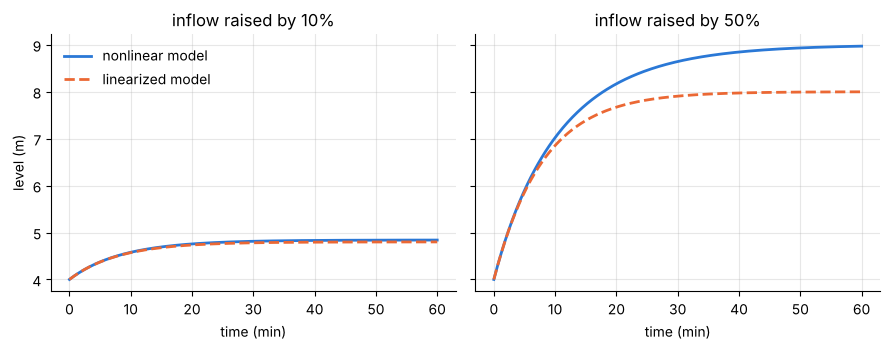

In [5]:
values = {A: 1.0, c: 0.5, q_s: 1.0}
h_s_val = float(steady_level.subs(values))
tau_val = float(tau.subs({**values, h_s: h_s_val}))
gain_val = float(gain.subs({**values, h_s: h_s_val}))
print(f"h_s = {h_s_val:.1f} m    tau = {tau_val:.1f} min    K = {gain_val:.1f} m per (m³/min)")

rate = sp.lambdify((h, q), dhdt.subs({A: values[A], c: values[c]}), "numpy")
times = np.linspace(0, 60, 300)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, step in zip(axes, (0.1, 0.5)):
    nonlinear = solve_ivp(lambda _, y: rate(y, values[q_s] + step), [0, 60], [h_s_val], t_eval=times, rtol=1e-8).y[0]
    linear = h_s_val + gain_val * step * (1 - np.exp(-times / tau_val))
    ax.plot(times, nonlinear, label="nonlinear model")
    ax.plot(times, linear, ls="--", label="linearized model")
    ax.set(xlabel="time (min)", title=f"inflow raised by {step:.0%}")
    if step == 0.1:
        assert abs(linear[-1] - nonlinear[-1]) / (nonlinear[-1] - h_s_val) < 0.06
axes[0].set_ylabel("level (m)")
axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout()

For a 10 % step the two models agree to within about 5 % of the level change. For a 50 % step
the linear model underestimates the final level by a metre.

## 9.2 Two states: the damped pendulum

**Problem.** $\ddot\theta = -c\,\dot\theta - \dfrac{g}{L}\sin\theta$. Find the equilibria and
decide which are stable.

Write the model as a first-order system in $(\theta, \omega)$ with $\omega = \dot\theta$.

In [6]:
theta, omega = sp.symbols("theta omega", real=True)
g, L, c_d = sp.symbols("g L c", positive=True)

state = sp.Matrix([theta, omega])
f = sp.Matrix([omega, -c_d * omega - g / L * sp.sin(theta)])

equilibria = sp.solve(list(f), [theta, omega], dict=True)
equilibria

[{ω: 0, θ: 0}, {ω: 0, θ: π}]

In [7]:
J = f.jacobian(state)
J

⎡    0       1 ⎤
⎢              ⎥
⎢-g⋅cos(θ)     ⎥
⎢──────────  -c⎥
⎣    L         ⎦

In [8]:
for point in equilibria:
    display(point, list(J.subs(point).eigenvals()))

{ω: 0, θ: 0}

⎡         ____________           ____________⎤
⎢        ╱    2                 ╱    2       ⎥
⎢  c   ╲╱  L⋅c  - 4⋅g     c   ╲╱  L⋅c  - 4⋅g ⎥
⎢- ─ - ───────────────, - ─ + ───────────────⎥
⎣  2        2⋅√L          2        2⋅√L      ⎦

{ω: 0, θ: π}

⎡         ____________           ____________⎤
⎢        ╱    2                 ╱    2       ⎥
⎢  c   ╲╱  L⋅c  + 4⋅g     c   ╲╱  L⋅c  + 4⋅g ⎥
⎢- ─ - ───────────────, - ─ + ───────────────⎥
⎣  2        2⋅√L          2        2⋅√L      ⎦

- **Hanging down** ($\theta = 0$): both eigenvalues have negative real part for any damping
  $c > 0$. Stable. They are complex when $c^2 < 4g/L$, which is the oscillating case.
- **Inverted** ($\theta = \pi$): one eigenvalue is always positive. Unstable (a saddle point).

**Verify** the two statements for specific numbers.

In [9]:
numbers = {g: 9.81, L: 1.0, c_d: 0.5}
down = [complex(e.subs(numbers)) for e in J.subs(equilibria[0]).eigenvals()]
up = [complex(e.subs(numbers)) for e in J.subs(equilibria[1]).eigenvals()]
assert all(e.real < 0 for e in down) and any(e.real > 0 for e in up)
down, up

([(-0.25-3.1220986531498327j), (-0.25+3.1220986531498327j)],
 [(-3.3920534686729953+0j), (2.8920534686729953+0j)])

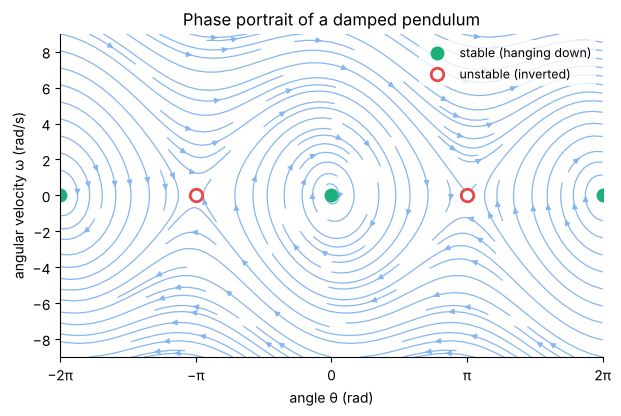

In [10]:
# phase portrait: the arrows are the lambdified right-hand side
f_num = sp.lambdify((theta, omega), list(f.subs(numbers)), "numpy")
TH, OM = np.meshgrid(np.linspace(-2 * np.pi, 2 * np.pi, 300), np.linspace(-9, 9, 300))
dTH, dOM = f_num(TH, OM)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.streamplot(TH, OM, dTH, dOM, color="#86b6ef", density=1.3, linewidth=0.9, arrowsize=0.8)
ax.plot([-2 * np.pi, 0, 2 * np.pi], [0, 0, 0], "o", color="#1baf7a", ms=9, label="stable (hanging down)")
ax.plot([-np.pi, np.pi], [0, 0], "o", mfc="white", mec="#e34948", mew=2, ms=9, label="unstable (inverted)")
ax.set(xlabel="angle θ (rad)", ylabel="angular velocity ω (rad/s)", title="Phase portrait of a damped pendulum")
ax.set_xticks(np.pi * np.arange(-2, 3), ["−2π", "−π", "0", "π", "2π"])
ax.grid(False)
ax.legend(frameon=True, facecolor="white", edgecolor="none", loc="upper right", fontsize=9);

Every trajectory spirals into a hanging-down equilibrium; the inverted positions repel.

## 9.3 Stability that depends on an operating parameter: a continuous bioreactor

**Problem.** In a chemostat, cells (concentration $x$) grow on a substrate ($s$) fed at
concentration $s_f$. The dilution rate $D$ is flow rate divided by volume. With Monod kinetics
$\mu(s) = \dfrac{\mu_{max}\,s}{K_s + s}$ and yield $Y$:

$$\dot x = \big(\mu(s) - D\big)\,x, \qquad \dot s = D\,(s_f - s) - \frac{\mu(s)\,x}{Y}.$$

If the reactor is run too fast, the cells are flushed out faster than they grow ("washout").
At what dilution rate does this happen?

In [11]:
x, s = sp.symbols("x s", nonnegative=True)
D, mu_max, K_s, s_f, Y = sp.symbols("D mu_max K_s s_f Y", positive=True)

mu = mu_max * s / (K_s + s)
reactor = sp.Matrix([(mu - D) * x, D * (s_f - s) - mu * x / Y])

steady_states = sp.solve(list(reactor), [x, s], dict=True)
steady_states

⎡                ⎧    -D⋅Kₛ       Y⋅(D⋅Kₛ + s_f⋅(D - μₘₐₓ))⎫⎤
⎢{s: s_f, x: 0}, ⎨s: ────────, x: ─────────────────────────⎬⎥
⎣                ⎩   D - μₘₐₓ             D - μₘₐₓ         ⎭⎦

Two steady states: **washout** ($x = 0$, nothing consumed) and a **productive** state.
Their stability comes from the eigenvalues of the Jacobian.

In [12]:
J_reactor = reactor.jacobian([x, s])
eigen = {}
for name, point in zip(("washout", "productive"), steady_states):
    eigen[name] = [sp.factor(sp.simplify(e)) for e in J_reactor.subs(point).eigenvals()]
    display(sp.Symbol(name), eigen[name])

washout

⎡-(D⋅Kₛ + D⋅s_f - μₘₐₓ⋅s_f)     ⎤
⎢───────────────────────────, -D⎥
⎣         Kₛ + s_f              ⎦

productive

⎡    -(D - μₘₐₓ)⋅(D⋅Kₛ + D⋅s_f - μₘₐₓ⋅s_f) ⎤
⎢-D, ──────────────────────────────────────⎥
⎣                   Kₛ⋅μₘₐₓ                ⎦

One eigenvalue is always $-D$. The other changes sign at a critical dilution rate:

In [13]:
D_washout = sp.solve(sp.Eq(mu.subs(s, s_f), D), D)[0]
D_washout

μₘₐₓ⋅s_f
────────
Kₛ + s_f

That is simply the growth rate at the feed concentration, $\mu(s_f)$: below it the productive
state is stable, above it only washout is. **Verify** with numbers on both sides.

A caution that applies to every symbolic solution: `solve` returns all mathematical solutions,
including ones that make no physical sense. Always check signs and ranges.

In [14]:
params = {mu_max: 0.5, K_s: 0.2, s_f: 10.0, Y: 0.5}      # 1/h, g/L, g/L, g cells per g substrate
D_crit = float(D_washout.subs(params))
print(f"washout at D = {D_crit:.3f} 1/h")

def is_stable(name, dilution):
    return all(float(e.subs({**params, D: dilution})) < 0 for e in eigen[name])

assert is_stable("productive", 0.9 * D_crit) and not is_stable("washout", 0.9 * D_crit)
assert is_stable("washout", 1.01 * D_crit) and not is_stable("productive", 1.01 * D_crit)

# just above washout the "productive" solution is also unphysical: its cell concentration is negative
x_above = float(steady_states[1][x].subs({**params, D: 1.01 * D_crit}))
assert x_above < 0
print(f"x in the 'productive' state at 1.01 D_crit: {x_above:.2f} g/L")

washout at D = 0.490 1/h
x in the 'productive' state at 1.01 D_crit: -5.10 g/L


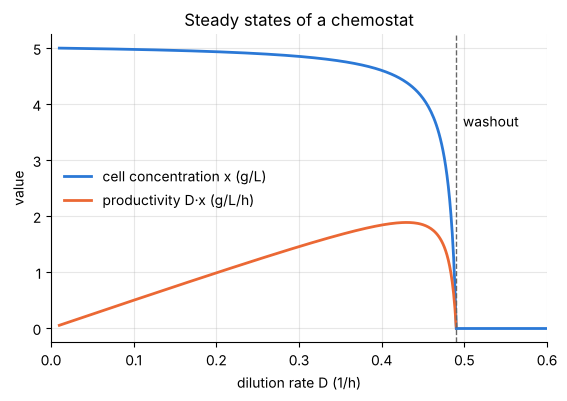

In [15]:
# steady-state biomass and productivity against dilution rate
x_productive = sp.lambdify(D, steady_states[1][x].subs(params), "numpy")
D_grid = np.linspace(0.01, D_crit, 300)

fig, ax = plt.subplots()
ax.plot(D_grid, x_productive(D_grid), label="cell concentration x (g/L)")
ax.plot(D_grid, D_grid * x_productive(D_grid), label="productivity D·x (g/L/h)")
ax.plot([D_crit, 0.6], [0, 0], color="#2a78d6")
ax.axvline(D_crit, color="0.4", lw=1, ls="--")
ax.annotate("washout", xy=(D_crit, 3.6), xytext=(D_crit + 0.008, 3.6))
ax.set(xlabel="dilution rate D (1/h)", ylabel="value", xlim=(0, 0.6), title="Steady states of a chemostat")
ax.legend(frameon=False, loc="center left");

The productivity peaks just before washout, so the most productive operating point is also the
most fragile one. This trade-off shapes how continuous fermenters are run.

In [16]:
# the dilution rate that maximizes productivity, found symbolically
productivity = D * steady_states[1][x]
candidates = sp.solve(sp.diff(productivity, D), D)
D_opt = [cand for cand in candidates if 0 < cand.subs(params) < D_crit][0]
sp.simplify(D_opt), float(D_opt.subs(params))

⎛    ____                                  ⎞
⎜  ╲╱ Kₛ ⋅μₘₐₓ                             ⎟
⎜- ──────────── + μₘₐₓ, 0.42998599579859953⎟
⎜    __________                            ⎟
⎝  ╲╱ Kₛ + s_f                             ⎠

## Summary

| Eigenvalues of the Jacobian at a steady state | Behaviour nearby |
| --- | --- |
| all real parts negative | stable: disturbances decay |
| any real part positive | unstable |
| complex pair | oscillation, decaying or growing according to the real part |
| a real part exactly zero | linearization cannot decide; the nonlinear terms matter |

## Exercises

1. Two tanks in series, each draining through a valve. Linearize, and show that the two
   eigenvalues are $-1/\tau_1$ and $-1/\tau_2$, where $\tau_i = 2A_i\sqrt{h_{is}}/c_i$ is the
   time constant of 9.1 for each tank.
2. For the pendulum, find the damping coefficient at which the hanging equilibrium changes
   from oscillatory to non-oscillatory.
3. The Lotka–Volterra model is $\dot x = x(a - b y)$, $\dot y = y(-c + d x)$. Find the
   coexistence steady state and its eigenvalues. What does a zero real part tell you?
4. Replace Monod kinetics in 9.3 by substrate inhibition,
   $\mu = \dfrac{\mu_{max}\,s}{K_s + s + s^2/K_i}$ with $K_i = 2$ g/L and the other parameters
   of 9.3. How many steady states are there at $D = 0.05$, $0.2$ and $0.4$ h⁻¹, and which are
   stable? (Use numbers; the symbolic solution is long.)